# Exploratory data analysis

Quick look at the raw Torob-style e-commerce tables that the rest of the project builds on
(products, brands, categories, shops, search logs, product views and clicks).

**Run it:** `pip install -e ".[eda]"`, put the raw `*.parquet` tables in `data/raw/` (see `data/README.md`), then run all cells.
The outputs saved in this notebook come from the original run on the full dataset.

## 1. Load the raw tables

In [ ]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import seaborn as sns

# Configuration for better display
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 10)

# Dictionary to store dataframes
dfs = {}
from pathlib import Path

# Repository root = first parent directory containing pyproject.toml
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').exists())
data_dir = ROOT / 'data' / 'raw'

# Raw tables expected in data/raw/ (see data/README.md)
files = [
    'base_products.parquet', 'base_views.parquet', 'brands.parquet',
    'categories.parquet', 'cities.parquet', 'final_clicks.parquet',
    'members.parquet', 'searches.parquet', 'shops.parquet'
]

print("--- Loading Data ---")
for file in files:
    file_path = os.path.join(data_dir, file)
    if os.path.exists(file_path):
        key = file.replace('.parquet', '')
        # Load parquet file
        dfs[key] = pd.read_parquet(file_path)
        print(f"Loaded {key}: Shape {dfs[key].shape}")
    else:
        print(f"WARNING: {file} not found in {data_dir}")

print("\n--- Sample Data Inspection ---")
# Display first 2 rows of the most critical tables to verify schema
critical_tables = ['base_products', 'members', 'searches']
for table in critical_tables:
    if table in dfs:
        print(f"\nTable: {table}")
        display(dfs[table].head(2))

--- Loading Data ---
Loaded base_products: Shape (1022298, 8)
Loaded base_views: Shape (199916, 4)
Loaded brands: Shape (2025, 2)
Loaded categories: Shape (746, 3)
Loaded cities: Shape (651, 2)
Loaded final_clicks: Shape (17371, 4)
Loaded members: Shape (1948665, 4)
Loaded searches: Shape (588347, 9)
Loaded shops: Shape (23342, 4)

--- Sample Data Inspection ---

Table: base_products


,image_url,random_key,category_id,brand_id,english_name,persian_name,extra_features,members
0,https://image.torob.com/base/images/K1/aU/K1aU...,chjknu,338,-1,,فرش 700شانه اُپال فیروزه ای,"{""meterage"": [""12 m"", ""9 m"", ""6 m""], ""original...",[lqtdbp]
1,https://image.torob.com/base/images/vx/gL/vxgL...,ppndkv,2453,-1,چند رنگ,صندلی تاب مدل chioco,"{""originality"": """", ""stock_status"": ""new""}",[iufoou]



Table: members


,random_key,shop_id,price,base_random_key
0,lqtdbp,1314,17000000,chjknu
1,iufoou,10370,246000,ppndkv



Table: searches


,id,uid,page,session_id,timestamp,query,result_base_product_rks,category_id,category_brand_boosts
0,jhemij,lqnsla,0,jyhxbg,2025-09-13 00:00:00.133000+00:00,یخچال فریزر طرح ساید پاکشوما,"[wdekwx, kayrjk, axmhow, pusbts, wdekwx, uyyyj...",0,[]
1,wvrviu,eghedv,0,ytenxp,2025-09-13 00:00:00.675000+00:00,یخچال,"[vkjhbx, ijfyrp, cvwrbk, lsmvew, tnbxnb, rwovy...",0,[]


## 2. Data quality and referential integrity

In [2]:
# --- Step 2: Data Quality & Integrity Checks ---

print("--- Missing Values Analysis (Base Products) ---")
base_prod = dfs['base_products']
missing_counts = base_prod.isnull().sum()
missing_pct = (missing_counts / len(base_prod)) * 100
missing_df = pd.DataFrame({'Missing Count': missing_counts, 'Percent': missing_pct})
# Check for empty strings in text columns as well, which isnull() misses
missing_df.loc['empty_string_persian'] = [(base_prod['persian_name'] == '').sum(), (base_prod['persian_name'] == '').mean() * 100]
missing_df.loc['empty_string_english'] = [(base_prod['english_name'] == '').sum(), (base_prod['english_name'] == '').mean() * 100]
display(missing_df.sort_values(by='Percent', ascending=False))

print("\n--- Uniqueness Check ---")
duplicates = base_prod['random_key'].duplicated().sum()
print(f"Duplicate random_keys in base_products: {duplicates}")

print("\n--- Referential Integrity Check ---")
# 1. Check Categories
valid_cat_ids = set(dfs['categories']['id'])
prod_cat_ids = set(base_prod['category_id'].unique())
# 0 often means 'root' or 'uncategorized', let's see if 0 exists in categories or if it's a placeholder
invalid_cats = prod_cat_ids - valid_cat_ids
print(f"Invalid Category IDs found in Base Products: {len(invalid_cats)}")
if len(invalid_cats) > 0:
    print(f"Sample invalid category IDs: {list(invalid_cats)[:5]}")

# 2. Check Brands (-1 usually means no brand, we exclude it from 'invalid' check if -1 is not in brands table)
valid_brand_ids = set(dfs['brands']['id'])
prod_brand_ids = set(base_prod['brand_id'].unique())
# Remove -1 from check if it exists in product but not in brands table (assuming -1 is logic for null)
check_brand_ids = prod_brand_ids - {-1}
invalid_brands = check_brand_ids - valid_brand_ids
print(f"Invalid Brand IDs found in Base Products (excluding -1): {len(invalid_brands)}")

# 3. Check Shops in Members
valid_shop_ids = set(dfs['shops']['id'])
member_shop_ids = set(dfs['members']['shop_id'].unique())
invalid_shops = member_shop_ids - valid_shop_ids
print(f"Invalid Shop IDs found in Members: {len(invalid_shops)}")

--- Missing Values Analysis (Base Products) ---


,Missing Count,Percent
empty_string_english,944376.0,92.377761
image_url,3341.0,0.326813
empty_string_persian,2.0,0.000196
random_key,0.0,0.000000
category_id,0.0,0.000000
brand_id,0.0,0.000000
persian_name,0.0,0.000000
english_name,0.0,0.000000
members,0.0,0.000000
extra_features,0.0,0.000000



--- Uniqueness Check ---
Duplicate random_keys in base_products: 0

--- Referential Integrity Check ---
Invalid Category IDs found in Base Products: 0
Invalid Brand IDs found in Base Products (excluding -1): 0
Invalid Shop IDs found in Members: 0


## 3. Content distributions: name length, categories, prices

Products with 0 or invalid price: 2
Price Stats:
count             1022292.000000
mean           4801049265.313043
std         4188465152347.409180
min                     1.000000
25%                275000.000000
50%               1050000.000000
75%               4477250.000000
max      4190000043500000.000000
Name: price, dtype: object


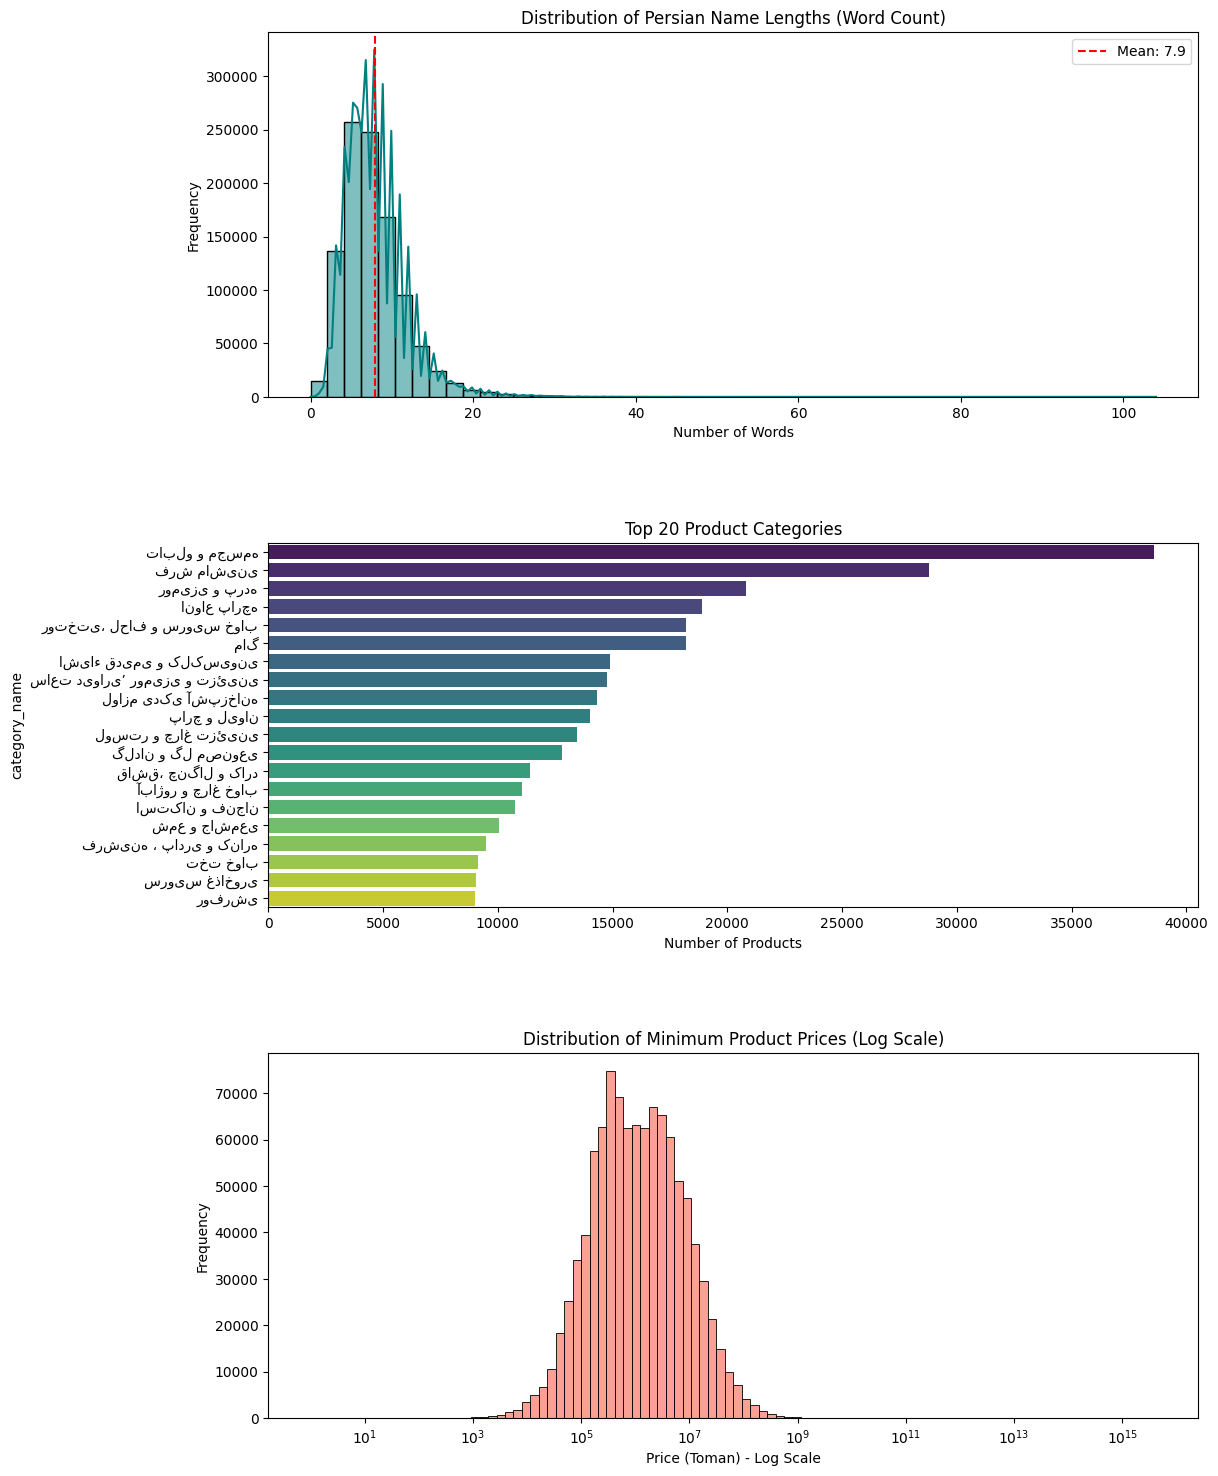

In [3]:
# --- Step 3: Content Analysis & Distributions ---

import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(3, 1, figsize=(12, 18))
plt.subplots_adjust(hspace=0.4)

# 1. Text Length Analysis (Word Count)
# specific tokenizers differ, but whitespace split is a good proxy for "words"
base_prod['name_length'] = base_prod['persian_name'].astype(str).apply(lambda x: len(x.split()))
sns.histplot(base_prod['name_length'], bins=50, kde=True, ax=axes[0], color='teal')
axes[0].set_title('Distribution of Persian Name Lengths (Word Count)')
axes[0].set_xlabel('Number of Words')
axes[0].set_ylabel('Frequency')
axes[0].axvline(base_prod['name_length'].mean(), color='r', linestyle='--', label=f"Mean: {base_prod['name_length'].mean():.1f}")
axes[0].legend()

# 2. Category Distribution (Top 20)
# Map category_id to actual names for readability
cat_map = dict(zip(dfs['categories']['id'], dfs['categories']['title']))
base_prod['category_name'] = base_prod['category_id'].map(cat_map)

top_cats = base_prod['category_name'].value_counts().head(20)
sns.barplot(x=top_cats.values, y=top_cats.index, ax=axes[1], palette='viridis')
axes[1].set_title('Top 20 Product Categories')
axes[1].set_xlabel('Number of Products')

# 3. Price Distribution (Aggregated from Members)
# We need to link members back to base products to get a "Base Product Price" (e.g., min price available)
# Since members is huge, we'll aggregate carefully
min_prices = dfs['members'].groupby('base_random_key')['price'].min()
# Remove 0 or negative prices for log scale visualization
valid_prices = min_prices[min_prices > 0]

sns.histplot(valid_prices, bins=100, log_scale=True, ax=axes[2], color='salmon')
axes[2].set_title('Distribution of Minimum Product Prices (Log Scale)')
axes[2].set_xlabel('Price (Toman) - Log Scale')
axes[2].set_ylabel('Frequency')

# Stats for Prices
zero_prices = (min_prices <= 0).sum()
print(f"Products with 0 or invalid price: {zero_prices}")
print(f"Price Stats:\n{valid_prices.describe().apply(lambda x: format(x, 'f'))}")

plt.show()

## 4. Search and interaction funnel

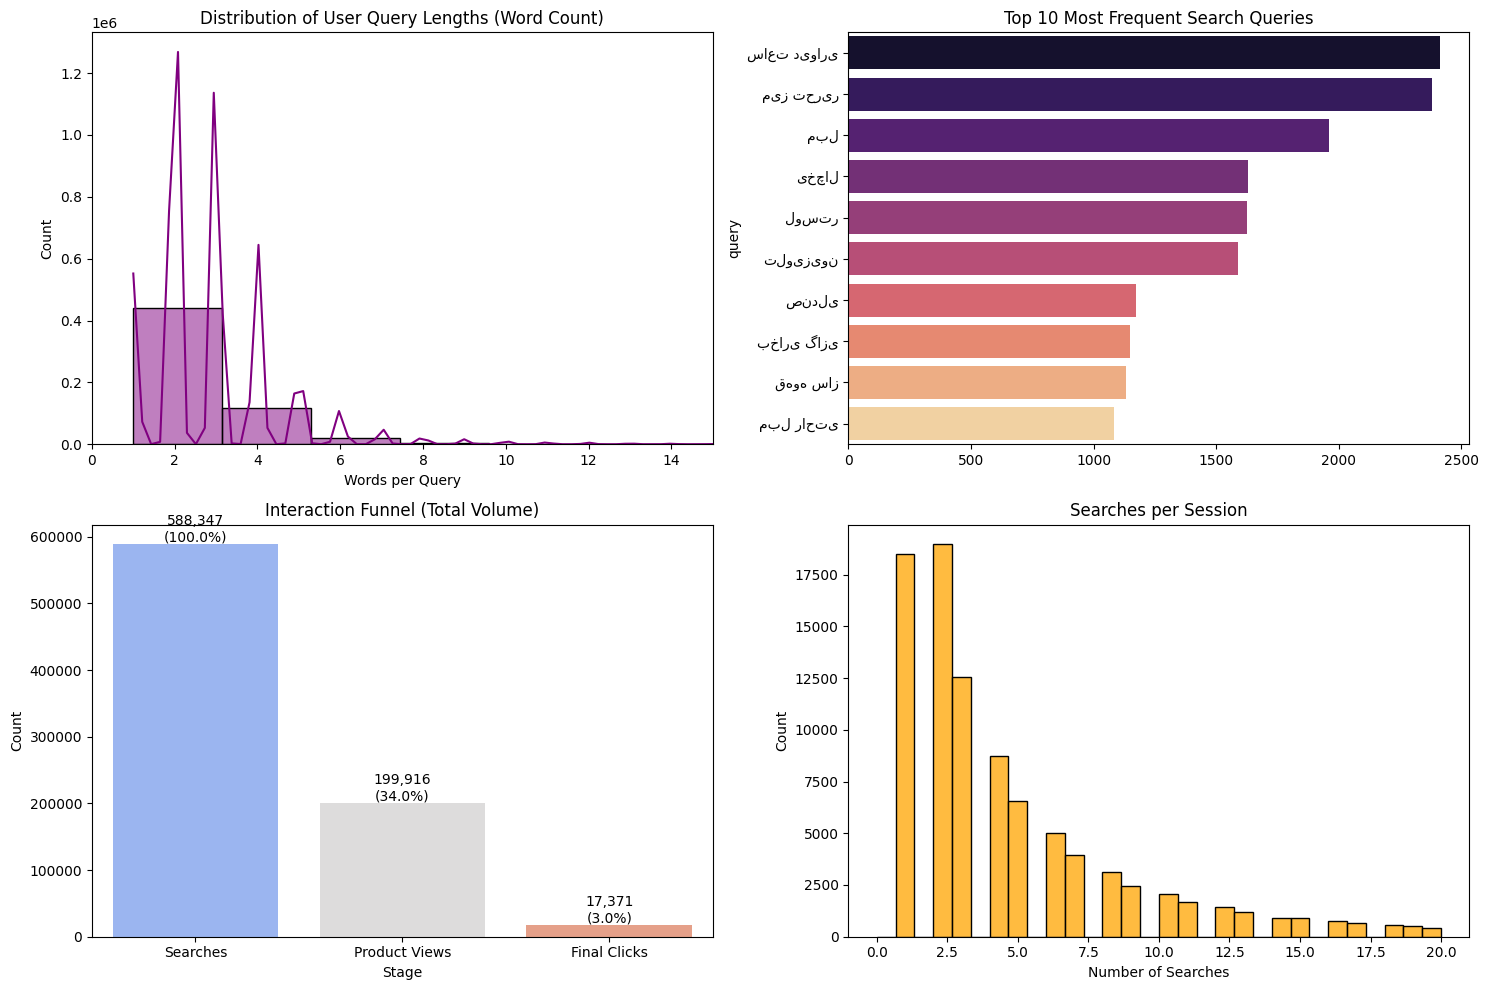

--- Top Queries ---
query
ساعت دیواری    2412
میز تحریر      2380
مبل            1961
یخچال          1629
لوستر          1626
تلویزیون       1590
صندلی          1173
بخاری گازی     1149
قهوه ساز       1134
مبل راحتی      1082
Name: count, dtype: int64


In [4]:
# --- Step 4: Search & Interaction Analysis ---

# 1. Query Length Analysis
searches = dfs['searches']
searches['query_length'] = searches['query'].astype(str).apply(lambda x: len(x.split()))

# 2. Funnel Analysis (Search -> View -> Click)
# We need to count unique IDs at each stage
n_searches = searches['id'].nunique()
n_views = dfs['base_views']['id'].nunique()
n_clicks = dfs['final_clicks']['id'].nunique()

# Calculate conversion ratios
search_to_view_rate = (n_views / n_searches) * 100
# Note: Views link to searches, Clicks link to Views.
# A rough funnel:
funnel_data = pd.DataFrame({
    'Stage': ['Searches', 'Product Views', 'Final Clicks'],
    'Count': [n_searches, n_views, n_clicks],
    'Conversion (%)': [100, search_to_view_rate, (n_clicks / n_searches) * 100]
})

# 3. Visualization
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Query Length
sns.histplot(searches['query_length'], bins=20, kde=True, ax=axes[0, 0], color='purple')
axes[0, 0].set_title('Distribution of User Query Lengths (Word Count)')
axes[0, 0].set_xlabel('Words per Query')
axes[0, 0].set_xlim(0, 15)

# Top 10 Queries
top_queries = searches['query'].value_counts().head(10)
sns.barplot(x=top_queries.values, y=top_queries.index, ax=axes[0, 1], palette='magma')
axes[0, 1].set_title('Top 10 Most Frequent Search Queries')

# Funnel Chart
sns.barplot(data=funnel_data, x='Stage', y='Count', ax=axes[1, 0], palette='coolwarm')
axes[1, 0].set_title('Interaction Funnel (Total Volume)')
for index, row in funnel_data.iterrows():
    axes[1, 0].text(index, row.Count, f"{row.Count:,}\n({row['Conversion (%)']:.1f}%)", 
                    color='black', ha="center", va="bottom")

# Search Sessions
# How many searches does a user do in one session?
session_counts = searches.groupby('session_id')['id'].count()
sns.histplot(session_counts, bins=30, binrange=(0, 20), ax=axes[1, 1], color='orange')
axes[1, 1].set_title('Searches per Session')
axes[1, 1].set_xlabel('Number of Searches')

plt.tight_layout()
plt.show()

print("--- Top Queries ---")
print(top_queries)

## 5. Query-product pairs and product features

In [5]:
# --- Step 5: specific Relevance Analysis & Feature Inspection ---

# 1. Create Positive Pairs (Query -> Clicked Product)
# Merge Searches -> Views (on search_id) -> Products (on base_product_rk)
# We use inner joins to find confirmed interactions
merged_df = (
    dfs['base_views'][['search_id', 'base_product_rk']]
    .merge(dfs['searches'][['id', 'query']], left_on='search_id', right_on='id')
    .drop(columns=['id'])  # drop redundant search id
    .merge(dfs['base_products'][['random_key', 'persian_name', 'category_id', 'extra_features']], 
           left_on='base_product_rk', right_on='random_key')
)

print(f"Total Positive Pairs (Query-Product) found: {len(merged_df)}")
print("\n--- Sample User Queries & The Products They Clicked ---")
display(merged_df[['query', 'persian_name']].sample(10, random_state=42))

# 2. Inspect Extra Features
# Let's see what's inside the JSONs for two distinct categories: 
# One from 'Home' (e.g., Carpet/Rug) and one from 'Electronics' (need to find a phone/digital cat)

import json

def extract_keys(json_str):
    try:
        data = json.loads(json_str)
        if isinstance(data, dict):
            return list(data.keys())
        return []
    except:
        return []

# Add category names for easier filtering
cat_map = dict(zip(dfs['categories']['id'], dfs['categories']['title']))
merged_df['category_name'] = merged_df['category_id'].map(cat_map)

# Sample 1: Carpets (Likely top category)
print("\n--- Feature Keys in 'Carpet' (Home) Category ---")
carpet_samples = merged_df[merged_df['category_name'].str.contains('فرش', na=False)].head(3)
for idx, row in carpet_samples.iterrows():
    print(f"Product: {row['persian_name']}")
    print(f"Features: {row['extra_features'][:100]}...") # truncate for display

# Sample 2: Mobile/Digital (if exists in sample)
print("\n--- Feature Keys in Electronics/Digital ---")
# Searching for keywords like 'Mobile', 'Phone', 'Digital', 'گوشی'
tech_samples = merged_df[merged_df['category_name'].str.contains('گوشی|موبایل', na=False)].head(3)
if not tech_samples.empty:
    for idx, row in tech_samples.iterrows():
        print(f"Product: {row['persian_name']}")
        print(f"Features: {row['extra_features'][:100]}...")
else:
    print("No phones found in the merged sample subset.")

Total Positive Pairs (Query-Product) found: 199916

--- Sample User Queries & The Products They Clicked ---


,query,persian_name
65557,کشتی تابلو,تابلو کشتی تایتانیک 3 Titanic ship
4403,ست پذیرایی سرامیکی سبز,ست پذیرایی حلقه سبز
74989,سرویس غذاخوری طلاکوب,ست غذاخوری لوکس طلاکوب ترک
145182,تابلو چراغ,تابلو خندالو طرح چراغ در برف
25738,گاز مازندران,اجاق گاز صفحه ای اخوان مدل Z4 با ۵ شعله
104514,یخچال کوچک,یخچال 9 فوت ایستکول
114398,جارو برقی بوش ۲۱pow2,جاروبرقی مخزن دار بوش مدل BGS21POW2
68257,سینی پذیرایی,سینی پذیرایی چوبی مستطیل دسته دار نرده ای طلایی
22675,کباب پز خانگی,کباب پز لعابی
5526,یخچال فریزر تکنو,یخچال فریزر تکنو ظرفیت ۲۵ فوت



--- Feature Keys in 'Carpet' (Home) Category ---
Product: فرش ماشینی فانتزی شگی ۱۲ متری زمینه کرم ۳۲۰ شانه
Features: {"meterage": ["12 m"], "originality": "", "number_combs": "320 \u0634\u0627\u0646\u0647", "stock_sta...
Product: فرش ماشینی ۷۰۰ شانه طرح مرمر ۱۲ متری با تراکم ۱۵۰۰ رنگ صدفی
Features: {"meterage": ["12 m"], "originality": "", "number_combs": "700 \u0634\u0627\u0646\u0647", "stock_sta...
Product: فرش اتاق خواب بزرگسال
Features: {"meterage": "", "originality": "", "number_combs": "", "stock_status": "new", "carpet_density": "",...

--- Feature Keys in Electronics/Digital ---
No phones found in the merged sample subset.
